# Laboratorio 17 — Máquinas de vectores de soporte

Una máquina de vectores de soporte (*support vector machine*, SVM) entrenada con
`scikit-learn` devuelve un objeto con tres atributos que resumen todo lo que aprendió:
los vectores de soporte, sus coeficientes duales y el intercepto. Este laboratorio parte
de esos tres atributos, reconstruye con ellos la función de decisión, y después usa el
modelo ya entendido para responder dos preguntas metodológicas:

> ¿Cómo se eligen el precio de la holgura $C$ y el ancho del kernel $\gamma$ **sin mirar el
> conjunto de prueba**, y cuánto se puede confiar en el error que reporta esa elección?
>
> Un kernel RBF puede dibujar fronteras que un hiperplano no puede. ¿Por qué, entonces, hay
> problemas reales en los que **el kernel lineal gana**?

El laboratorio tiene cuatro ejercicios. Cada uno empieza con el desarrollo teórico que
practica, sigue con la consigna y la celda a completar, y termina con una verificación o
con preguntas de análisis sobre los resultados obtenidos:

| Ejercicio | Qué se escribe | Cómo se cierra |
|---|---|---|
| 1. La función de decisión, desde el dual | `kernel_rbf` y `funcion_decision` | **Verificación** contra `rbf_kernel` y `SVC.decision_function` |
| 2. El precio de la holgura | `barrer_C`: errores, vectores de soporte y margen para cada $C$ | Preguntas de análisis |
| 3. Ajustar $(C,\gamma)$ con entrenamiento, validación y prueba | `buscar_grilla` | **Verificación** contra `GridSearchCV` + decisión y análisis |
| 4. Lineal contra RBF | `comparar_kernels`, sobre tres conjuntos de datos | Preguntas de análisis y conclusión |

Las celdas que contienen `raise NotImplementedError()` deben completarse; el resto es
andamiaje y se ejecuta sin modificar. Después de cada bloque de preguntas hay una celda
**Respuesta** que debe completarse con lo observado: los números del propio notebook son la
evidencia.

**Notación.** La de la unidad de SVM: etiquetas $y_i\in\{-1,+1\}$, función de decisión
$h(\mathbf x)=\mathbf w^\top\mathbf x+b$ con predicción $\operatorname{sign}h(\mathbf x)$,
multiplicadores $\alpha_i\ge0$, conjunto de vectores de soporte
$\mathcal S=\{i:\alpha_i>0\}$, holguras $\xi_i$, precio $C$, kernel $K(\mathbf x,\mathbf x')$
y ancho del RBF $\gamma$.

**Datos de lunas: demostración provisional.** Falta el CSV original del curso; las cifras siguientes corresponden a `make_moons(600, noise=0.25, random_state=42)` y deben recalcularse con `lunas_svm.csv`. Las cifras de wdbc y meatspec sí usan los CSV del curso.



## 0. Preparación

In [1]:
from __future__ import annotations

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.model_selection import GridSearchCV, PredefinedSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEMILLA = 42

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

AZUL, TURQUESA, NARANJA = "#19326E", "#50ACB0", "#CD742A"
VIOLETA, OLIVA, GRIS = "#A3477F", "#89A943", "#8A8A8A"

### Los tres conjuntos de datos

- **Lunas** (`lunas_svm.csv`, $600\times3$). Dos medias lunas entrelazadas con ruido, en
  el plano. Ningún hiperplano las separa: es el conjunto de los ejercicios 1 a 3, donde la
  frontera se puede **ver**. Sintético, con semilla fija.
- **wdbc** (*Wisconsin Diagnostic Breast Cancer*, $569\times32$). Diez medidas de los
  núcleos celulares de una punción de mama —radio, textura, perímetro, área, suavidad,
  compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal—, cada una resumida
  por su media, su error estándar y su peor valor: $p=30$. Respuesta: diagnóstico maligno
  (`M`, $+1$) o benigno (`B`, $-1$).
- **meatspec** (Tecator, $215\times101$). Espectros de absorbancia en el infrarrojo
  cercano de $215$ muestras de carne picada, medidos en $100$ longitudes de onda entre
  $850$ y $1050$ nm, y el contenido de grasa de cada muestra. La respuesta se binariza:
  grasa por encima de la mediana ($+1$) o no ($-1$).

Las lunas se leen de `data/`; los dos conjuntos reales se descargan del repositorio de
datasets del curso. Si no hay conexión, la celda busca copias locales; para wdbc el plan B
es `load_breast_cancer` de `scikit-learn`, que contiene exactamente los mismos datos.

In [2]:
#@title Carga de los conjuntos de datos (ejecutar sin modificar) { display-mode: "form" }
URL_DATASETS = "https://raw.githubusercontent.com/gustavovazquez/datasets/main/"


def buscar_local(nombre: str) -> Path | None:
    candidatas = [Path("data") / nombre, Path("../data") / nombre, Path("../../data") / nombre, Path(nombre)]
    return next((c for c in candidatas if c.exists()), None)


def leer(nombre: str, plan_b=None) -> pd.DataFrame:
    """Lee `nombre` de disco, del repositorio de datasets, del plan B o, en Colab, de una subida."""
    ruta = buscar_local(nombre)
    if ruta is not None:
        print(f"{nombre:<16} origen: {ruta}")
        return pd.read_csv(ruta)
    try:
        tabla = pd.read_csv(URL_DATASETS + nombre)
        print(f"{nombre:<16} origen: repositorio de datasets")
        return tabla
    except Exception:
        if plan_b is not None:
            print(f"{nombre:<16} origen: plan B local")
            return plan_b()
    from google.colab import files                 # type: ignore
    files.upload()
    return pd.read_csv(nombre)


def wdbc_desde_sklearn() -> pd.DataFrame:
    bc = load_breast_cancer()
    tabla = pd.DataFrame(bc.data)
    tabla.insert(0, "Diagnosis", np.where(bc.target == 0, "M", "B"))
    return tabla


if buscar_local("lunas_svm.csv") is not None:
    lunas = leer("lunas_svm.csv")
    LUNAS_ORIGINALES = True
else:
    from sklearn.datasets import make_moons
    print("AVISO: falta lunas_svm.csv del curso. Se usa una DEMOSTRACIÓN con make_moons(n_samples=600, noise=0.25, random_state=42). Los resultados de lunas no son los del archivo original.")
    X_demo, y_demo = make_moons(n_samples=600, noise=0.25, random_state=42)
    lunas = pd.DataFrame({"x1": X_demo[:, 0], "x2": X_demo[:, 1], "y": 2 * y_demo - 1})
    LUNAS_ORIGINALES = False
wdbc = leer("wdbc.csv", plan_b=wdbc_desde_sklearn)
meat = leer("meatspec.csv")

X_lunas = lunas[["x1", "x2"]].to_numpy()
y_lunas = lunas["y"].to_numpy()

X_wdbc = wdbc.drop(columns=["ID", "Diagnosis"], errors="ignore").to_numpy(dtype=float)
y_wdbc = np.where(wdbc["Diagnosis"] == "M", 1, -1)

X_meat = meat.filter(regex=r"^V\d+$").to_numpy(dtype=float)
grasa = meat["fat"].to_numpy()
y_meat = np.where(grasa > np.median(grasa), 1, -1)

assert X_lunas.shape == (600, 2) and set(y_lunas) == {-1, 1}
assert X_wdbc.shape == (569, 30) and X_meat.shape == (215, 100)
for nombre, y in [("lunas", y_lunas), ("wdbc", y_wdbc), ("meatspec", y_meat)]:
    print(f"{nombre:<9} n = {len(y):>3}   positivos: {np.mean(y == 1):.3f}")

AVISO: falta lunas_svm.csv del curso. Se usa una DEMOSTRACIÓN con make_moons(n_samples=600, noise=0.25, random_state=42). Los resultados de lunas no son los del archivo original.
wdbc.csv         origen: data\wdbc.csv
meatspec.csv     origen: data\meatspec.csv
lunas     n = 600   positivos: 0.500
wdbc      n = 569   positivos: 0.373
meatspec  n = 215   positivos: 0.493


### Andamiaje común

Tres funciones que se usan en todo el laboratorio y no hay que escribir:

- `particionar` separa un conjunto en **entrenamiento** ($60\ \%$), **validación**
  ($20\ \%$) y **prueba** ($20\ \%$), estratificando por la clase. El ejercicio 3 explica
  para qué sirve cada parte.
- `error` es la proporción de observaciones mal clasificadas.
- `dibujar_frontera` pinta las regiones de decisión de un modelo en el plano, la frontera
  $h(\mathbf x)=0$, las dos líneas del margen $h(\mathbf x)=\pm1$ y los vectores de soporte
  rodeados por un círculo.

In [3]:
def particionar(X: np.ndarray, y: np.ndarray, semilla: int = SEMILLA):
    """Particion estratificada 60/20/20: (X_ent, X_val, X_pru, y_ent, y_val, y_pru)."""
    X_resto, X_pru, y_resto, y_pru = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=semilla)
    X_ent, X_val, y_ent, y_val = train_test_split(
        X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=semilla)
    return X_ent, X_val, X_pru, y_ent, y_val, y_pru


def error(modelo, X: np.ndarray, y: np.ndarray) -> float:
    """Proporcion de observaciones mal clasificadas."""
    return float(np.mean(modelo.predict(X) != y))


def dibujar_frontera(ax, modelo, X: np.ndarray, y: np.ndarray, titulo: str = "",
                     vectores: np.ndarray | None = None) -> None:
    """Regiones de decision, frontera h = 0, margen h = +-1 y vectores de soporte."""
    x1 = np.linspace(X[:, 0].min() - 0.4, X[:, 0].max() + 0.4, 300)
    x2 = np.linspace(X[:, 1].min() - 0.4, X[:, 1].max() + 0.4, 300)
    G1, G2 = np.meshgrid(x1, x2)
    H = modelo.decision_function(np.c_[G1.ravel(), G2.ravel()]).reshape(G1.shape)
    ax.contourf(G1, G2, H > 0, levels=[-0.5, 0.5, 1.5], colors=[NARANJA, AZUL], alpha=0.12)
    ax.contour(G1, G2, H, levels=[-1, 0, 1], colors=[GRIS, "k", GRIS],
               linestyles=["--", "-", "--"], linewidths=[1, 1.6, 1])
    ax.scatter(*X[y == 1].T, s=10, color=AZUL, label="$y=+1$")
    ax.scatter(*X[y == -1].T, s=10, color=NARANJA, label="$y=-1$")
    if vectores is not None:
        ax.scatter(*vectores.T, s=45, facecolors="none", edgecolors="k", linewidths=0.7,
                   label="vector de soporte")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(titulo)


X_ent, X_val, X_pru, y_ent, y_val, y_pru = particionar(X_lunas, y_lunas)
print("entrenamiento", X_ent.shape, " validacion", X_val.shape, " prueba", X_pru.shape)

entrenamiento (360, 2)  validacion (120, 2)  prueba (120, 2)


---

# 1. La función de decisión, desde el dual

### Teoría

El clasificador de margen blando resuelve el problema **primal**

$$
\min_{\mathbf w,b,\boldsymbol\xi}\ \tfrac12\lVert\mathbf w\rVert^2+C\sum_{i=1}^n\xi_i
\qquad\text{sujeto a}\qquad y_i(\mathbf w^\top\mathbf x_i+b)\ge1-\xi_i,\quad \xi_i\ge0 .
$$

Con un multiplicador $\alpha_i\ge0$ por cada restricción de margen, la condición de
estacionariedad del lagrangiano respecto de $\mathbf w$ es

$$
\frac{\partial\mathcal L}{\partial\mathbf w}=\mathbf w-\sum_{i=1}^n\alpha_iy_i\mathbf x_i=\mathbf 0
\quad\Longrightarrow\quad
\mathbf w=\sum_{i=1}^n\alpha_iy_i\mathbf x_i ,
$$

y respecto de $b$ da $\sum_i\alpha_iy_i=0$. Sustituyendo $\mathbf w$ en la función de
decisión:

$$
h(\mathbf x)=\mathbf w^\top\mathbf x+b=\sum_{i=1}^n\alpha_iy_i\,\mathbf x_i^\top\mathbf x+b .
$$

Dos hechos convierten esta expresión en el método completo.

**Primero: solo cuentan los vectores de soporte.** La holgura complementaria de las
condiciones de Karush-Kuhn-Tucker (KKT) dice que
$\alpha_i\,[\,y_ih(\mathbf x_i)-1+\xi_i\,]=0$: una observación que queda estrictamente
fuera del margen, del lado correcto, tiene $\alpha_i=0$ y desaparece de la suma. Las que
tienen $\alpha_i>0$ son los **vectores de soporte**, y la suma corre solo sobre ellos:

$$
h(\mathbf x)=\sum_{i\in\mathcal S}\alpha_iy_i\,\mathbf x_i^\top\mathbf x+b .
$$

**Segundo: los datos entran solo a través de productos internos.** Si las observaciones se
llevan a otro espacio con una transformación $\phi$, el producto
$\mathbf x_i^\top\mathbf x$ pasa a ser $\phi(\mathbf x_i)^\top\phi(\mathbf x)$. Un
**kernel** es una función que calcula ese producto sin construir $\phi$:
$K(\mathbf x,\mathbf x')=\phi(\mathbf x)^\top\phi(\mathbf x')$. Con él, la función de
decisión queda

$$
\boxed{\;h(\mathbf x)=\sum_{i\in\mathcal S}\alpha_iy_i\,K(\mathbf x_i,\mathbf x)+b\;}
$$

El kernel de base radial (*radial basis function*, RBF) es

$$
K(\mathbf x,\mathbf x')=\exp\!\left(-\gamma\,\lVert\mathbf x-\mathbf x'\rVert^2\right),
\qquad \gamma>0,
$$

y para calcularlo sobre dos matrices de observaciones sin un doble ciclo conviene
desarrollar el cuadrado de la norma:

$$
\lVert\mathbf a-\mathbf b\rVert^2=\lVert\mathbf a\rVert^2+\lVert\mathbf b\rVert^2-2\,\mathbf a^\top\mathbf b .
$$

Para una matriz $\mathbf A$ de $m$ filas y una $\mathbf B$ de $k$ filas, el término
$\mathbf a^\top\mathbf b$ de todos los pares es el producto matricial
$\mathbf A\mathbf B^\top$, de forma $m\times k$; las dos normas son un vector columna y un
vector fila que se suman por *broadcasting*.

**Dónde guarda cada cosa `scikit-learn`.** Un `SVC` ya ajustado expone:

| Atributo | Contenido | Forma |
|---|---|---|
| `support_vectors_` | Los $\mathbf x_i$ con $i\in\mathcal S$ | $(\lvert\mathcal S\rvert,\,p)$ |
| `dual_coef_` | Los productos $\alpha_iy_i$, **con el signo de la etiqueta incluido** | $(1,\,\lvert\mathcal S\rvert)$ |
| `intercept_` | El intercepto $b$ | $(1,)$ |

Además, el problema dual de margen blando acota los multiplicadores: $0\le\alpha_i\le C$.
Junto con $\sum_i\alpha_iy_i=0$, son dos propiedades que `dual_coef_` tiene que cumplir.

### Consigna

1. Implementar `kernel_rbf(A, B, gamma)`, que devuelve la matriz de kernel entre las filas
   de `A` y las de `B`, usando el desarrollo de la norma. No se permite usar
   `rbf_kernel` ni un ciclo sobre las observaciones.
2. Implementar `funcion_decision(X, modelo, gamma)`, que calcula $h(\mathbf x)$ para cada
   fila de `X` con la expresión recuadrada, usando **solamente** los tres atributos de la
   tabla. No se permite llamar a `modelo.decision_function`.

El modelo es un `SVC` con kernel RBF, $C=1$ y $\gamma=1$, ajustado sobre el conjunto de
entrenamiento de las lunas.

In [4]:
GAMMA_1, C_1 = 1.0, 1.0
modelo_1 = SVC(kernel="rbf", C=C_1, gamma=GAMMA_1).fit(X_ent, y_ent)
print(f"vectores de soporte: {modelo_1.support_vectors_.shape}   dual_coef_: {modelo_1.dual_coef_.shape}"
      f"   intercept_: {modelo_1.intercept_}")

vectores de soporte: (91, 2)   dual_coef_: (1, 91)   intercept_: [0.06076929]


In [5]:
def kernel_rbf(A, B, gamma):
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    dist2 = (np.sum(A * A, axis=1)[:, None]
             + np.sum(B * B, axis=1)[None, :] - 2 * A @ B.T)
    dist2 = np.maximum(dist2, 0.0)  # corrige redondeos negativos
    return np.exp(-gamma * dist2)


def funcion_decision(X, modelo, gamma):
    K = kernel_rbf(X, modelo.support_vectors_, gamma)
    return K @ modelo.dual_coef_.ravel() + modelo.intercept_[0]


In [6]:
# VERIFICACIÓN — el kernel y la funcion de decision coinciden con los de scikit-learn
K_propio = kernel_rbf(X_val, X_ent, GAMMA_1)
assert K_propio.shape == (len(X_val), len(X_ent)), f"forma {K_propio.shape}: se esperaba (m, k)"
assert np.allclose(K_propio, rbf_kernel(X_val, X_ent, gamma=GAMMA_1)), "kernel_rbf no coincide con rbf_kernel"

h_propia = funcion_decision(X_val, modelo_1, GAMMA_1)
assert h_propia.shape == (len(X_val),), f"forma {h_propia.shape}: se esperaba (m,)"
assert np.allclose(h_propia, modelo_1.decision_function(X_val)), "funcion_decision no coincide con decision_function"
assert np.array_equal(np.sign(h_propia), modelo_1.predict(X_val)), "el signo de h deberia ser la prediccion"

# las dos propiedades del dual: sum alpha_i y_i = 0 y 0 <= alpha_i <= C
alfa_y = modelo_1.dual_coef_.ravel()
assert np.isclose(alfa_y.sum(), 0, atol=1e-8), "sum alpha_i y_i deberia ser 0"
assert np.all(np.abs(alfa_y) <= C_1 + 1e-8), "algun alpha_i supera a C"
print("VERIFICACIÓN SUPERADA.\n")

n_S = len(alfa_y)
acotados = np.isclose(np.abs(alfa_y), C_1)
print(f"vectores de soporte: {n_S} de {len(X_ent)} observaciones de entrenamiento")
print(f"  con alpha_i = C (sobre el margen o violandolo):  {acotados.sum()}")
print(f"  con 0 < alpha_i < C (exactamente sobre el margen): {(~acotados).sum()}")

VERIFICACIÓN SUPERADA.

vectores de soporte: 91 de 360 observaciones de entrenamiento
  con alpha_i = C (sobre el margen o violandolo):  81
  con 0 < alpha_i < C (exactamente sobre el margen): 10


La función reconstruida permite comprobar la consecuencia más fuerte de KKT: **una
observación que no es vector de soporte no influye en el modelo**. La celda siguiente
retira del entrenamiento la observación con mayor $y_ih(\mathbf x_i)$ —la más lejos de la
frontera, del lado correcto— y, por contraste, uno de los vectores de soporte con
$0<\alpha_i<C$; reajusta en los dos casos y mide cuánto cambia $h$ sobre validación.

observacion mas lejana   y*h =  2.090  es vector de soporte: False   cambio maximo de h: 0.00e+00
vector de soporte libre  y*h =  1.000  es vector de soporte: True   cambio maximo de h: 6.97e-02


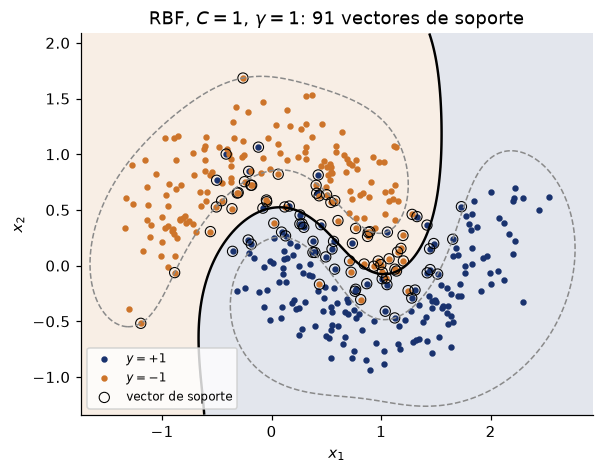

In [7]:
def cambio_al_retirar(indice: int) -> float:
    """Maximo cambio de h sobre validacion al reajustar sin la observacion `indice`."""
    resto = np.delete(np.arange(len(X_ent)), indice)
    reajustado = SVC(kernel="rbf", C=C_1, gamma=GAMMA_1).fit(X_ent[resto], y_ent[resto])
    return float(np.max(np.abs(funcion_decision(X_val, reajustado, GAMMA_1) - h_propia)))


margen_firmado = y_ent * funcion_decision(X_ent, modelo_1, GAMMA_1)
lejana = int(np.argmax(margen_firmado))
libre = int(modelo_1.support_[~acotados][0])

print(f"observacion mas lejana   y*h = {margen_firmado[lejana]:6.3f}  es vector de soporte: "
      f"{lejana in modelo_1.support_}   cambio maximo de h: {cambio_al_retirar(lejana):.2e}")
print(f"vector de soporte libre  y*h = {margen_firmado[libre]:6.3f}  es vector de soporte: "
      f"{libre in modelo_1.support_}   cambio maximo de h: {cambio_al_retirar(libre):.2e}")

fig, ax = plt.subplots(figsize=(6, 4.5))
dibujar_frontera(ax, modelo_1, X_ent, y_ent, f"RBF, $C={C_1:g}$, $\\gamma={GAMMA_1:g}$: "
                 f"{n_S} vectores de soporte", vectores=modelo_1.support_vectors_)
ax.legend(loc="lower left", fontsize=8)
plt.show()

### Para analizar

1. ¿Qué fracción de las observaciones de entrenamiento es vector de soporte? Para predecir
   una observación nueva, ¿cuántas evaluaciones del kernel hacen falta, y de qué depende ese
   número? Comparar con el costo de predecir con una regresión logística.
2. Retirar la observación más lejana no cambia $h$; retirar un vector de soporte libre sí.
   Explicar los dos resultados con la holgura complementaria. ¿Qué diferencia esto de una
   regresión logística, donde toda observación entra en la verosimilitud?
3. En el gráfico, ¿dónde están los vectores de soporte con $\alpha_i=C$ y dónde los que
   tienen $0<\alpha_i<C$? Relacionar con el valor de $y_ih(\mathbf x_i)$ que impone KKT en
   cada caso.

**Datos de lunas: demostración provisional.** Falta el CSV original del curso; las cifras siguientes corresponden a `make_moons(600, noise=0.25, random_state=42)` y deben recalcularse con `lunas_svm.csv`. Las cifras de wdbc y meatspec sí usan los CSV del curso.

**Respuesta:**

1. Hay 91/360 = 25,28 % de vectores de soporte. Cada predicción necesita 91 evaluaciones del kernel RBF, una por soporte: depende del número de soportes, determinado por los datos, C y gamma. El costo es del orden de n_vs × p. Una regresión logística calcula un producto wᵀx y una sigmoide, con costo del orden de p, independiente del número de ejemplos usados para entrenar.
2. La observación más lejana tiene y·h = 2,090, queda fuera del margen y no es soporte: alpha=0 y no aporta a la expansión dual. Retirarla cambia h en 0,00 en esta ejecución. El soporte libre tiene y·h≈1 y alpha>0: su restricción está activa; retirarlo obliga a reajustar y el cambio máximo es 0,0697. En una regresión logística todos los ejemplos aportan a la verosimilitud, aunque un ejemplo muy bien clasificado puede aportar muy poco. En general, al reajustar una SVM pueden aparecer pequeñas diferencias por tolerancias numéricas o por soluciones no únicas.
3. Los 10 soportes libres, con 0<alpha<C, están sobre las líneas de margen h=±1, con y·h=1 y holgura cero. Los 81 acotados, con alpha=C, cumplen y·h≤1: pueden estar sobre el margen, dentro de él o mal clasificados. Si 0<y·h<1 aciertan dentro del margen; si y·h<0 se equivocan. Tener alpha=C no significa necesariamente una clasificación incorrecta.


---

# 2. El precio de la holgura

### Teoría

En el primal, $C$ es el **precio** de cada unidad de holgura $\xi_i$: cuánto se paga, en
la función objetivo, por cada observación que entra en el margen o lo cruza. Con dos
multiplicadores —$\alpha_i$ para la restricción de margen y $\mu_i\ge0$ para
$\xi_i\ge0$—, la estacionariedad respecto de $\xi_i$ es

$$
\frac{\partial\mathcal L}{\partial\xi_i}=C-\alpha_i-\mu_i=0
\quad\Longrightarrow\quad
\alpha_i=C-\mu_i\le C ,
$$

que es la cota $0\le\alpha_i\le C$ del ejercicio anterior. La holgura complementaria
$\mu_i\xi_i=0$ completa la clasificación de los vectores de soporte:

| Caso | $\alpha_i$ | Posición |
|---|---|---|
| No es vector de soporte | $0$ | Fuera del margen, del lado correcto: $y_ih(\mathbf x_i)\ge1$ |
| Vector de soporte **libre** | $0<\alpha_i<C$ | Entonces $\mu_i>0$, $\xi_i=0$: exactamente sobre el margen, $y_ih(\mathbf x_i)=1$ |
| Vector de soporte **acotado** | $\alpha_i=C$ | Dentro del margen o del lado equivocado: $\xi_i\ge0$, $y_ih(\mathbf x_i)\le1$ |

**El margen se calcula en el espacio del kernel.** El margen geométrico es
$M=1/\lVert\mathbf w\rVert$. Con un kernel, $\mathbf w=\sum_{i\in\mathcal S}\alpha_iy_i\,\phi(\mathbf x_i)$
vive en un espacio que no se construye, pero su norma sí se calcula:

$$
\lVert\mathbf w\rVert^2=\mathbf w^\top\mathbf w
=\sum_{i\in\mathcal S}\sum_{j\in\mathcal S}\alpha_iy_i\,\alpha_jy_j\,\phi(\mathbf x_i)^\top\phi(\mathbf x_j)
=\mathbf c^\top\mathbf K_{\mathcal S}\,\mathbf c ,
$$

donde $\mathbf c$ es el vector de los $\alpha_iy_i$ —`dual_coef_`— y $\mathbf K_{\mathcal S}$
la matriz de kernel entre los vectores de soporte. Entonces
$M=1/\sqrt{\mathbf c^\top\mathbf K_{\mathcal S}\,\mathbf c}$.

**$C$ es una regularización.** Cada $\xi_i$ óptimo vale
$\max\{0,\,1-y_ih(\mathbf x_i)\}$, la **pérdida bisagra** (*hinge loss*); dividiendo el
primal por $nC$, el mismo problema se escribe como pérdida más penalización,

$$
\min_{\mathbf w,b}\ \frac1n\sum_{i=1}^n\max\{0,\,1-y_ih(\mathbf x_i)\}+\lambda\lVert\mathbf w\rVert^2,
\qquad \lambda=\frac{1}{2nC},
$$

con la misma solución. **$C$ grande es poca regularización**: la holgura es cara, el
ajuste persigue cada observación y el margen se angosta. $C$ chico es mucha
regularización: violar el margen es barato, el margen se ensancha y muchas observaciones
quedan dentro de él.

### Consigna

Implementar `barrer_C(Cs, gamma)`: para cada $C$ de la lista, ajustar un `SVC` RBF sobre el
entrenamiento de las lunas y registrar los errores de entrenamiento y de validación, el
número de vectores de soporte, cuántos de ellos están acotados ($\lvert\alpha_iy_i\rvert=C$,
con `np.isclose`) y el margen $M$ calculado con la fórmula de arriba y la función
`kernel_rbf` del ejercicio 1.

Este ejercicio no tiene verificación automática: el control es que los números tengan
sentido a la luz de la teoría, y eso es lo que piden las preguntas.

In [8]:
def barrer_C(Cs, gamma):
    filas = []
    for C in Cs:
        m = SVC(kernel="rbf", C=C, gamma=gamma).fit(X_ent, y_ent)
        c = m.dual_coef_.ravel()
        K = kernel_rbf(m.support_vectors_, m.support_vectors_, gamma)
        norma2 = float(c @ K @ c)
        filas.append({"C": C,
                      "err_entrenamiento": error(m, X_ent, y_ent),
                      "err_validacion": error(m, X_val, y_val),
                      "n_vs": len(m.support_),
                      "n_acotados": int(np.isclose(np.abs(c), C).sum()),
                      "margen": 1 / np.sqrt(norma2) if norma2 > 0 else np.inf})
    return pd.DataFrame(filas).set_index("C")


In [9]:
CS_2 = [0.01, 0.1, 1, 10, 100, 1000]
barrido = barrer_C(CS_2, gamma=GAMMA_1)
print(barrido.round(4).to_string())

         err_entrenamiento  err_validacion  n_vs  n_acotados  margen
C                                                                   
0.01                0.1306          0.1333   360         360  0.8729
0.10                0.0861          0.0750   176         166  0.3441
1.00                0.0556          0.0500    91          81  0.1931
10.00               0.0500          0.0667    67          53  0.0938
100.00              0.0528          0.0917    59          37  0.0506
1000.00             0.0528          0.0833    53          33  0.0195


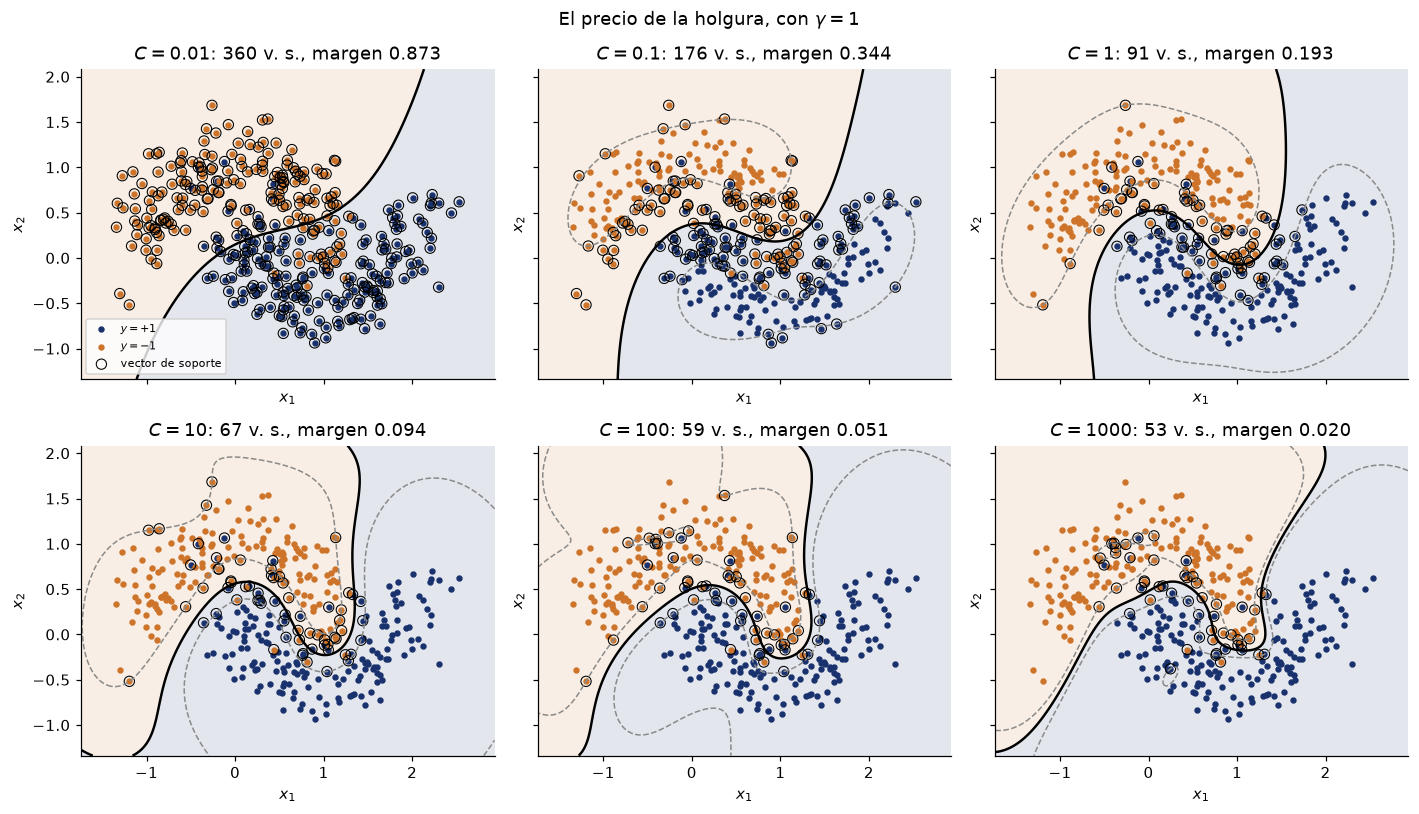

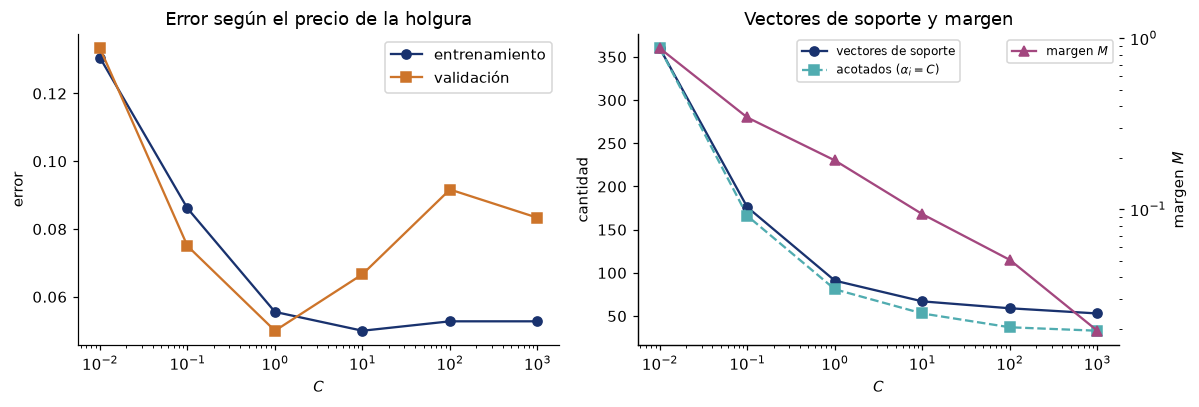

In [10]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True, sharey=True)
for ax, C in zip(ejes.ravel(), CS_2):
    m = SVC(kernel="rbf", C=C, gamma=GAMMA_1).fit(X_ent, y_ent)
    dibujar_frontera(ax, m, X_ent, y_ent, vectores=m.support_vectors_,
                     titulo=f"$C={C:g}$: {len(m.support_)} v. s., margen {barrido.loc[C, 'margen']:.3f}")
ejes[0, 0].legend(loc="lower left", fontsize=7)
fig.suptitle(f"El precio de la holgura, con $\\gamma={GAMMA_1:g}$")
plt.tight_layout()
plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(CS_2, barrido["err_entrenamiento"], "o-", color=AZUL, label="entrenamiento")
a1.plot(CS_2, barrido["err_validacion"], "s-", color=NARANJA, label="validación")
a1.set_xscale("log"); a1.set_xlabel("$C$"); a1.set_ylabel("error"); a1.legend()
a1.set_title("Error según el precio de la holgura")
a2.plot(CS_2, barrido["n_vs"], "o-", color=AZUL, label="vectores de soporte")
a2.plot(CS_2, barrido["n_acotados"], "s--", color=TURQUESA, label="acotados ($\\alpha_i=C$)")
a2.set_xscale("log"); a2.set_xlabel("$C$"); a2.set_ylabel("cantidad")
a3 = a2.twinx(); a3.plot(CS_2, barrido["margen"], "^-", color=VIOLETA, label="margen $M$")
a3.set_yscale("log"); a3.set_ylabel("margen $M$")
a2.legend(loc="upper center", fontsize=8); a3.legend(loc="upper right", fontsize=8)
a2.set_title("Vectores de soporte y margen")
plt.tight_layout()
plt.show()

### Para analizar

1. ¿Cómo cambian el margen $M$ y el número de vectores de soporte al aumentar $C$?
   Explicarlo con el papel de $C$ como precio de la holgura.
2. Con el $C$ más chico, **todas** las observaciones de entrenamiento son vectores de
   soporte y todas están acotadas. ¿Qué significa eso geométricamente? ¿Por qué el error
   no es, aun así, el de una clasificación al azar?
3. ¿En qué valor de $C$ se alcanza el menor error de validación? A cada lado de ese valor,
   ¿el modelo está en régimen de subajuste o de sobreajuste? Justificar con la brecha entre
   entrenamiento y validación y con la forma de las fronteras.
4. Para $C\ge10$ el error de entrenamiento casi no baja, pero la frontera sigue cambiando.
   ¿Qué parámetro impide que el error de entrenamiento llegue a cero, y qué tendría que
   cambiar para que lo hiciera?

**Datos de lunas: demostración provisional.** Falta el CSV original del curso; las cifras siguientes corresponden a `make_moons(600, noise=0.25, random_state=42)` y deben recalcularse con `lunas_svm.csv`. Las cifras de wdbc y meatspec sí usan los CSV del curso.

**Respuesta:**

1. Al aumentar C de 0,01 a 1000, el margen cae de 0,8729 a 0,0195 y los soportes bajan de 360 a 53; los acotados pasan de 360 a 33. La holgura resulta más cara, se reduce la regularización y el modelo acepta una norma mayor para penalizar las violaciones del margen. Estas son tendencias observadas, no una garantía de monotonía del número de soportes en cualquier dataset.
2. Con C=0,01, las 360 observaciones tienen alpha=C y y·h≤1: todas están sobre el margen o lo violan, pero no todas cruzan la frontera h=0. El margen es muy ancho. El error es 0,1306 en entrenamiento y 0,1333 en validación, muy inferior a 0,5: aun con fuerte regularización se aprende estructura de las clases.
3. El mínimo de validación está en C=1: 0,0500, frente a 0,0556 de entrenamiento. Con C=0,01 ambos errores son altos (0,1306 y 0,1333), evidencia de subajuste. Con C=10, 100 y 1000, entrenamiento queda alrededor de 0,05, mientras validación sube a 0,0667, 0,0917 y 0,0833; la mayor brecha y las fronteras más adaptadas a los puntos sugieren sobreajuste. No se espera monotonía estricta del error de clasificación.
4. En el rango probado, gamma=1 mantiene un radio de influencia amplio y limita la flexibilidad práctica; aumentar gamma junto con ajustar C permitiría fronteras más locales y potencialmente error cero. Hay un matiz: gamma fijo no impone una imposibilidad matemática de interpolar. El RBF con gamma>0 puede separar etiquetas de puntos distintos con un C suficientemente grande; aquí se observa un límite práctico para C≤1000, no una barrera absoluta. Etiquetas contradictorias sobre el mismo punto sí impedirían error cero.


---

# 3. Ajustar $(C,\gamma)$ con entrenamiento, validación y prueba

### Teoría

**El papel de $\gamma$.** En $K(\mathbf x,\mathbf x')=\exp(-\gamma\lVert\mathbf x-\mathbf x'\rVert^2)$,
la influencia de un vector de soporte cae a $e^{-1}$ a la distancia $r=1/\sqrt\gamma$: ese
es su **radio de influencia**. Los dos extremos se leen en el propio kernel:

- $\gamma\to\infty$: $K(\mathbf x_i,\mathbf x_j)\to0$ para $i\ne j$ y la matriz de kernel
  tiende a la identidad. Cada observación de entrenamiento es una isla que solo se ve a sí
  misma: el modelo **memoriza**.
- $\gamma\to0$: $K\to1$ para todo par, y desarrollando la exponencial a primer orden,
  $K(\mathbf x,\mathbf x')\approx1-\gamma\lVert\mathbf x\rVert^2-\gamma\lVert\mathbf x'\rVert^2+2\gamma\,\mathbf x^\top\mathbf x'$:
  lo único que distingue a dos observaciones es el producto interno, y la frontera tiende
  a la de un **kernel lineal**.

$C$ y $\gamma$ interactúan —los dos controlan la flexibilidad— y se ajustan juntos, sobre
una grilla.

**Por qué tres particiones.** Cada conjunto responde a una pregunta distinta y no puede
responder dos:

| Partición | Qué se decide con ella |
|---|---|
| Entrenamiento ($60\ \%$) | Los parámetros del modelo: los $\alpha_i$ y $b$, para cada $(C,\gamma)$ |
| Validación ($20\ \%$) | Los hiperparámetros: qué $(C,\gamma)$ se elige |
| Prueba ($20\ \%$) | Nada. Solo **estima** el error del modelo elegido, una vez, al final |

El error de validación del modelo elegido **no** es una estimación honesta de su error.
Si $\hat e_1,\dots,\hat e_G$ son los errores de validación de las $G$ celdas de la grilla,
cada uno con ruido, el elegido es el mínimo, y el mínimo de variables ruidosas está sesgado
hacia abajo:

$$
\mathbb E\Big[\min_g \hat e_g\Big]\ \le\ \min_g\,\mathbb E[\hat e_g] .
$$

Cuantas más celdas tiene la grilla, más oportunidades hay de que alguna salga baja por
azar. Por eso hace falta un tercer conjunto que no haya participado de ninguna decisión.

**La resolución de la validación.** Un error estimado sobre $n_{\text{val}}$
observaciones es una proporción, con desvío estándar
$\sqrt{\hat e(1-\hat e)/n_{\text{val}}}$. Con $n_{\text{val}}=120$ y $\hat e\approx0{,}05$
eso es $0{,}020$: **dos celdas cuyos errores difieren en menos que eso no se distinguen**.

**El escalado se ajusta con el entrenamiento.** El RBF depende de distancias, y las
distancias de las escalas de los atributos: se estandariza. La media y el desvío se
estiman **solo con el entrenamiento** y se aplican a validación y prueba; un `Pipeline`
lo garantiza. Estimarlos con todos los datos filtra información de validación y prueba al
modelo.

### Consigna

Implementar `buscar_grilla(X_ent, y_ent, X_val, y_val, kernel, Cs, gammas)`: para cada
combinación, ajustar `make_pipeline(StandardScaler(), SVC(kernel=kernel, C=C, gamma=gamma))`
**sobre entrenamiento**, medir el error **sobre validación** y registrar el número de
vectores de soporte. Con `kernel="linear"`, $\gamma$ no interviene: se recorre solo $C$ y
la columna `gamma` queda en `np.nan`.

La función se reutiliza en el ejercicio 4 con otros conjuntos de datos: por eso recibe las
particiones como argumentos y no usa las variables globales.

In [11]:
def buscar_grilla(X_ent, y_ent, X_val, y_val, kernel, Cs, gammas):
    if kernel not in {"linear", "rbf"}:
        raise ValueError("kernel debe ser linear o rbf")
    filas = []
    for C in Cs:
        for gamma in (gammas if kernel == "rbf" else [np.nan]):
            parametros = {"kernel": kernel, "C": C}
            if kernel == "rbf":
                parametros["gamma"] = gamma
            m = make_pipeline(StandardScaler(), SVC(**parametros))
            m.fit(X_ent, y_ent)
            filas.append({"C": C, "gamma": gamma,
                          "err_validacion": error(m, X_val, y_val),
                          "n_vs": len(m[-1].support_)})
    return (pd.DataFrame(filas, columns=["C", "gamma", "err_validacion", "n_vs"])
            .sort_values(["err_validacion", "n_vs"], kind="stable")
            .reset_index(drop=True))


In [12]:
CS_3 = [0.01, 0.1, 1, 10, 100, 1000]
GAMMAS_3 = [0.01, 0.1, 1, 10, 100]
grilla = buscar_grilla(X_ent, y_ent, X_val, y_val, "rbf", CS_3, GAMMAS_3)

# VERIFICACIÓN — la grilla coincide con GridSearchCV sobre la misma particion entrenamiento/validacion
assert list(grilla.columns) == ["C", "gamma", "err_validacion", "n_vs"], "columnas"
assert len(grilla) == len(CS_3) * len(GAMMAS_3), f"{len(grilla)} filas: deberia haber una por combinacion"
assert grilla["err_validacion"].is_monotonic_increasing, "la tabla deberia estar ordenada por error de validacion"

X_ev = np.vstack([X_ent, X_val])
y_ev = np.concatenate([y_ent, y_val])
particion = PredefinedSplit(np.r_[-np.ones(len(y_ent)), np.zeros(len(y_val))])   # -1: siempre entrenamiento
referencia = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf")),
                          {"svc__C": CS_3, "svc__gamma": GAMMAS_3},
                          cv=particion, refit=False).fit(X_ev, y_ev)
ref = pd.DataFrame(referencia.cv_results_["params"]).rename(columns={"svc__C": "C", "svc__gamma": "gamma"})
ref["err_ref"] = 1 - referencia.cv_results_["mean_test_score"]
comparado = grilla.merge(ref, on=["C", "gamma"])
assert len(comparado) == len(grilla), "las combinaciones no coinciden con las de la referencia"
assert np.allclose(comparado["err_validacion"], comparado["err_ref"]), "los errores de validacion no coinciden"

lineal = buscar_grilla(X_ent, y_ent, X_val, y_val, "linear", CS_3, GAMMAS_3)
assert len(lineal) == len(CS_3) and lineal["gamma"].isna().all(), "con kernel lineal: una fila por C y gamma = nan"
print("VERIFICACIÓN SUPERADA.\n")

print(grilla.head(8).round(4).to_string())

VERIFICACIÓN SUPERADA.

         C  gamma  err_validacion  n_vs
0     1.00    1.0          0.0500    91
1  1000.00    0.1          0.0667    73
2     0.01   10.0          0.0667   360
3  1000.00    1.0          0.0750    58
4   100.00    1.0          0.0750    63
5   100.00    0.1          0.0750    88
6     0.10    1.0          0.0750   179
7    10.00    1.0          0.0833    65


mejor celda: C = 1, gamma = 1, error de validacion 0.0500
resolucion de la validacion: 0.0199
celdas a menos de una resolucion de la mejor: 3
         C  gamma  err_validacion  n_vs
0     1.00    1.0          0.0500    91
1  1000.00    0.1          0.0667    73
2     0.01   10.0          0.0667   360


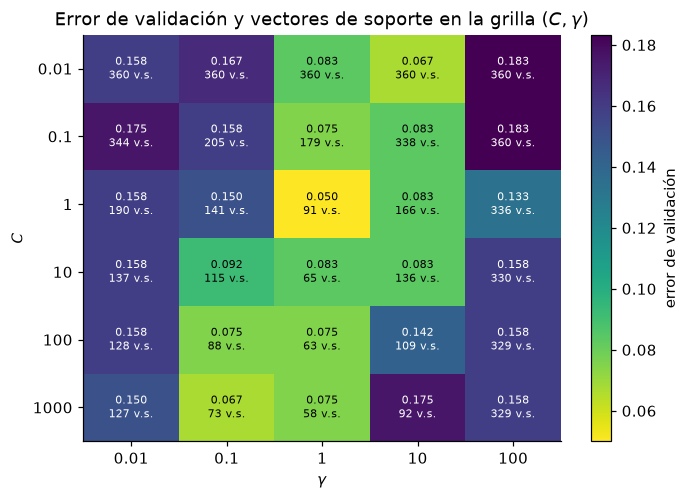

In [13]:
errores = grilla.pivot(index="C", columns="gamma", values="err_validacion")
vectores = grilla.pivot(index="C", columns="gamma", values="n_vs")

fig, ax = plt.subplots(figsize=(7, 4.8))
im = ax.imshow(errores.values, cmap="viridis_r", aspect="auto")
for i in range(errores.shape[0]):
    for j in range(errores.shape[1]):
        ax.text(j, i, f"{errores.values[i, j]:.3f}\n{int(vectores.values[i, j])} v.s.",
                ha="center", va="center", fontsize=7.5,
                color="white" if errores.values[i, j] > errores.values.mean() else "black")
ax.set_xticks(range(len(GAMMAS_3)), [f"{g:g}" for g in GAMMAS_3])
ax.set_yticks(range(len(CS_3)), [f"{c:g}" for c in CS_3])
ax.set_xlabel("$\\gamma$"); ax.set_ylabel("$C$")
ax.set_title("Error de validación y vectores de soporte en la grilla $(C,\\gamma)$")
fig.colorbar(im, ax=ax, label="error de validación")
plt.show()

mejor = grilla.iloc[0]
resolucion = np.sqrt(mejor.err_validacion * (1 - mejor.err_validacion) / len(y_val))
empatadas = grilla[grilla.err_validacion <= mejor.err_validacion + resolucion]
print(f"mejor celda: C = {mejor.C:g}, gamma = {mejor.gamma:g}, error de validacion {mejor.err_validacion:.4f}")
print(f"resolucion de la validacion: {resolucion:.4f}")
print(f"celdas a menos de una resolucion de la mejor: {len(empatadas)}")
print(empatadas.round(4).to_string())

### DECIDE

Con la tabla de celdas empatadas a la vista, fijar la configuración $(C,\gamma)$ que se
lleva al conjunto de prueba. El criterio no puede depender del conjunto de prueba, y tiene
que distinguir entre celdas que la validación no distingue.

In [14]:
# Criterio fijado antes de evaluar prueba: entre las celdas a menos
# de un error estándar de la mejor, preferir gamma menor (más suave)
# y luego C menor (más regularización). No se mira y_pru.
elegida = empatadas.sort_values(["gamma", "C"], kind="stable").iloc[0]
C_ELEGIDO = float(elegida.C)
GAMMA_ELEGIDO = float(elegida.gamma)


configuracion elegida: C = 1000, gamma = 0.1, 73 vectores de soporte
error de entrenamiento: 0.0528
error de validacion:    0.0667   (el que se uso para elegir)
error de prueba:        0.0667   (la estimacion que se reporta)
resolucion de la prueba: 0.0228


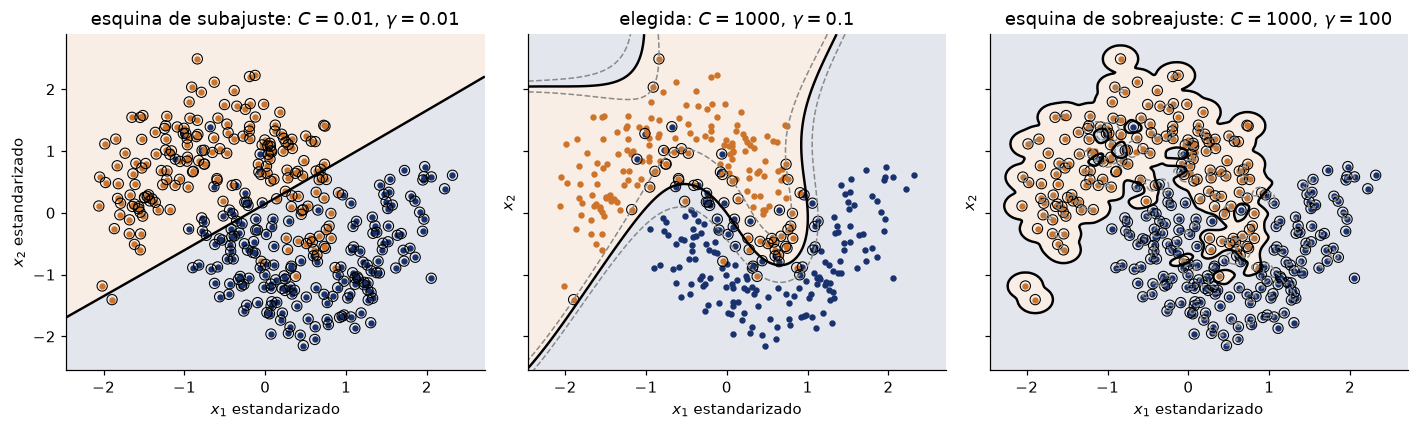

In [15]:
assert C_ELEGIDO is not None and GAMMA_ELEGIDO is not None, "falta fijar la configuracion elegida"
assert ((grilla.C == C_ELEGIDO) & (grilla.gamma == GAMMA_ELEGIDO)).any(), "la configuracion no esta en la grilla"

# el conjunto de prueba se usa una sola vez, con la configuracion ya fijada
final = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C_ELEGIDO, gamma=GAMMA_ELEGIDO)).fit(X_ent, y_ent)
err_val_elegido = grilla.loc[(grilla.C == C_ELEGIDO) & (grilla.gamma == GAMMA_ELEGIDO), "err_validacion"].item()
err_pru = error(final, X_pru, y_pru)
print(f"configuracion elegida: C = {C_ELEGIDO:g}, gamma = {GAMMA_ELEGIDO:g}, {len(final[-1].support_)} vectores de soporte")
print(f"error de entrenamiento: {error(final, X_ent, y_ent):.4f}")
print(f"error de validacion:    {err_val_elegido:.4f}   (el que se uso para elegir)")
print(f"error de prueba:        {err_pru:.4f}   (la estimacion que se reporta)")
print(f"resolucion de la prueba: {np.sqrt(err_pru * (1 - err_pru) / len(y_pru)):.4f}")

esquinas = [(CS_3[0], GAMMAS_3[0], "esquina de subajuste"), (C_ELEGIDO, GAMMA_ELEGIDO, "elegida"),
            (CS_3[-1], GAMMAS_3[-1], "esquina de sobreajuste")]
escalador = StandardScaler().fit(X_ent)
Z_ent = escalador.transform(X_ent)
fig, ejes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (C, g, rotulo) in zip(ejes, esquinas):
    m = SVC(kernel="rbf", C=C, gamma=g).fit(Z_ent, y_ent)
    dibujar_frontera(ax, m, Z_ent, y_ent, vectores=m.support_vectors_,
                     titulo=f"{rotulo}: $C={C:g}$, $\\gamma={g:g}$")
    ax.set_xlabel("$x_1$ estandarizado")
ejes[0].set_ylabel("$x_2$ estandarizado")
plt.tight_layout()
plt.show()

### Para analizar

1. Justificar el criterio usado en el `DECIDE` para elegir entre celdas empatadas. ¿Por qué
   no corresponde desempatar mirando el error de prueba?
2. Comparar el error de validación de la configuración elegida con su error de prueba.
   ¿Cuál se reporta como desempeño esperado del modelo, y por qué el otro tiende a ser
   optimista? ¿La diferencia observada supera la resolución de la prueba?
3. Leer las dos esquinas de la grilla. En la de $\gamma=100$, ¿qué pasa con el número de
   vectores de soporte y con la forma de la frontera? Relacionar con el radio de influencia
   $1/\sqrt\gamma$ y con la matriz de kernel que tiende a la identidad.
4. Si el `StandardScaler` se hubiera ajustado con las $600$ observaciones antes de
   particionar, ¿qué información del conjunto de prueba habría entrado en el modelo? ¿Por
   qué el efecto es chico en las lunas, y en qué tipo de datos sería grande?

**Datos de lunas: demostración provisional.** Falta el CSV original del curso; las cifras siguientes corresponden a `make_moons(600, noise=0.25, random_state=42)` y deben recalcularse con `lunas_svm.csv`. Las cifras de wdbc y meatspec sí usan los CSV del curso.

**Respuesta:**

1. Antes de mirar prueba, fijo este criterio: entre las celdas a menos de un error estándar del mínimo, elegir primero gamma menor, favoreciendo una influencia más amplia, y luego C menor, favoreciendo regularización. Las tres candidatas son (1,1), (1000,0,1) y (0,01,10); resulta C=1000, gamma=0,1. Es una preferencia de suavidad, no una afirmación de que C=1000 regularice más. Validación tiene resolución 0,0199 y no distingue con claridad errores 0,0500 y 0,0667. Usar prueba para desempatar la convertiría en otro conjunto de selección y sesgaría la estimación final.
2. Para la configuración elegida, validación y prueba dan 0,0667 (8 errores de 120); entrenamiento da 0,0528. Se reporta 0,0667 de prueba como estimación del desempeño del modelo ya elegido. Validación participó en la selección y tiende a ser optimista en promedio, aunque no tiene que ser menor en cada partición. La diferencia observada es cero y no supera la resolución de prueba, 0,0228. Un error estándar es una referencia de incertidumbre, no una prueba formal de igualdad.
3. Con C=0,01 y gamma=0,01 hay mucha regularización e influencia amplia: una frontera poco flexible, tendiente al subajuste. Con gamma=100, el radio en coordenadas estandarizadas es 0,1 y el kernel entre puntos suficientemente separados se aproxima a cero: aparecen numerosos soportes e islas de predicción alrededor de observaciones. En la esquina C=1000, gamma=100 hay 329 soportes de 360 y error de validación 0.1583. Con C=1000 la frontera se adapta muy localmente al entrenamiento y suele generalizar peor. La matriz tiende a la identidad al aumentar gamma si los puntos son distintos; gamma=100 no hace que todos sus términos fuera de la diagonal sean exactamente cero.
4. Ajustar StandardScaler con las 600 observaciones introduce sus medias y desvíos, incluidos los de prueba, en las distancias con que se entrena y valida. No filtra etiquetas, pero sí información sobre la distribución de atributos. En lunas, con atributos de escalas comparables y particiones de la misma distribución, el efecto suele ser pequeño; puede crecer con pocas observaciones, valores extremos, distribuciones cambiantes o escalas muy distintas. El pipeline debe ajustar el escalador solo sobre entrenamiento.


---

# 4. Lineal contra RBF: cuándo gana el lineal

### Teoría

**En teoría, el RBF no debería perder.** El desarrollo del ejercicio 3 muestra que, con
$\gamma\to0$, el kernel RBF se reduce a una constante, términos que dependen de cada
observación por separado y $2\gamma\,\mathbf x^\top\mathbf x'$: el kernel lineal, escalado.
Compensando la escala con un $C$ que crece como $1/\gamma$, la familia RBF **contiene** en
el límite a la lineal. Si hay un hiperplano bueno, algún $(C,\gamma)$ del RBF lo
aproxima.

**En la práctica, puede perder**, por tres motivos que el ejercicio mide:

1. **La esquina donde el RBF imita al lineal está lejos.** Hace falta $\gamma$ muy chico
   **y** $C$ muy grande a la vez; una grilla de valores habituales no llega, y extenderla
   hasta ahí multiplica el costo.
2. **Más hiperparámetros, más optimismo.** El lineal elige entre $|C|$ configuraciones;
   el RBF, entre $|C|\times|\gamma|$. Con la misma validación, el mínimo de una grilla más
   grande es más optimista (ejercicio 3), y la configuración elegida, más ruidosa.
3. **El RBF es isótropo.** $K$ depende solo de la distancia euclídea
   $\lVert\mathbf x-\mathbf x'\rVert$, que suma por igual todas las direcciones. Si casi
   toda la varianza de los datos está en unas pocas direcciones y la señal está en otras,
   la distancia mide lo que no importa y el kernel no ve la señal. Un hiperplano, en
   cambio, pondera cada dirección con su propio peso $w_j$, por chica que sea su varianza.

**Por qué la alta dimensión favorece al lineal.** Con $p$ atributos y $n\le p+1$
observaciones en posición general, **cualquier** etiquetado es separable por un
hiperplano: en dimensión alta, un hiperplano ya es muy flexible y la flexibilidad extra
del RBF solo agrega varianza. El rango efectivo de los datos se diagnostica con las
componentes principales: qué fracción de la varianza total captura cada dirección.

**Una sola partición no alcanza para comparar.** Con conjuntos de prueba de $43$ a $120$
observaciones, la resolución es de varios puntos porcentuales. La comparación se repite
sobre $20$ particiones con semillas distintas y se reporta la distribución, no un número.

### Consigna

Implementar `comparar_kernels(X, y, semilla, Cs, gammas)`. Para cada kernel —`"linear"` y
`"rbf"`—, con la partición `particionar(X, y, semilla)`:

1. elegir $(C,\gamma)$ con `buscar_grilla` del ejercicio 3 —la primera fila de la tabla—;
2. reajustar el pipeline con esa configuración sobre entrenamiento;
3. medir el error sobre el conjunto de prueba.

La celda siguiente la corre sobre los tres conjuntos de datos y $20$ semillas. Este
ejercicio no tiene verificación automática: el entregable es la lectura de los resultados.

In [16]:
def comparar_kernels(X, y, semilla, Cs, gammas):
    Xe, Xv, Xp, ye, yv, yp = particionar(X, y, semilla)
    filas = []
    for kernel in ["linear", "rbf"]:
        mejor = buscar_grilla(Xe, ye, Xv, yv, kernel, Cs, gammas).iloc[0]
        parametros = {"kernel": kernel, "C": float(mejor.C)}
        if kernel == "rbf":
            parametros["gamma"] = float(mejor.gamma)
        m = make_pipeline(StandardScaler(), SVC(**parametros)).fit(Xe, ye)
        filas.append({"kernel": kernel, "C": float(mejor.C),
                      "gamma": float(mejor.gamma),
                      "err_validacion": float(mejor.err_validacion),
                      "err_prueba": error(m, Xp, yp),
                      "n_vs": len(m[-1].support_)})
    return pd.DataFrame(filas).set_index("kernel")


In [17]:
CS_4 = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
GAMMAS_4 = [0.0001, 0.001, 0.01, 0.1, 1, 10]
SEMILLAS = range(20)
CONJUNTOS = {"lunas": (X_lunas, y_lunas), "wdbc": (X_wdbc, y_wdbc), "meatspec": (X_meat, y_meat)}

inicio = time.perf_counter()
registros = []
for nombre, (X, y) in CONJUNTOS.items():
    for s in SEMILLAS:
        tabla = comparar_kernels(X, y, s, CS_4, GAMMAS_4)
        for kernel, fila in tabla.iterrows():
            registros.append({"conjunto": nombre, "semilla": s, "kernel": kernel, **fila.to_dict()})
resultados = pd.DataFrame(registros)
print(f"{len(resultados)} ajustes finales en {time.perf_counter() - inicio:.1f} s\n")

resumen = (resultados.groupby(["conjunto", "kernel"], sort=False)
           [["err_validacion", "err_prueba", "n_vs"]].agg(["mean", "std"]).round(4))
print(resumen.to_string())

ancho = resultados.pivot_table(index=["conjunto", "semilla"], columns="kernel", values="err_prueba")
victorias = pd.DataFrame({
    "lineal gana": (ancho["linear"] < ancho["rbf"]).groupby("conjunto", sort=False).mean(),
    "empate": (ancho["linear"] == ancho["rbf"]).groupby("conjunto", sort=False).mean(),
    "RBF gana": (ancho["rbf"] < ancho["linear"]).groupby("conjunto", sort=False).mean()})
print("\nfraccion de particiones (error de prueba):")
print(victorias.round(2).to_string())

120 ajustes finales en 13.0 s

                err_validacion         err_prueba            n_vs         
                          mean     std       mean     std    mean      std
conjunto kernel                                                           
lunas    linear         0.1258  0.0218     0.1362  0.0244  137.40  53.0902
         rbf            0.0446  0.0125     0.0571  0.0151  109.50  74.1098
wdbc     linear         0.0180  0.0122     0.0390  0.0183   37.25  18.7417
         rbf            0.0158  0.0135     0.0390  0.0170   56.55  42.7471
meatspec linear         0.0198  0.0189     0.0233  0.0282   16.25   5.2703
         rbf            0.0547  0.0295     0.0814  0.0577   44.65  16.7906

fraccion de particiones (error de prueba):
          lineal gana  empate  RBF gana
conjunto                               
lunas             0.0    0.00      1.00
meatspec          0.8    0.15      0.05
wdbc              0.3    0.35      0.35


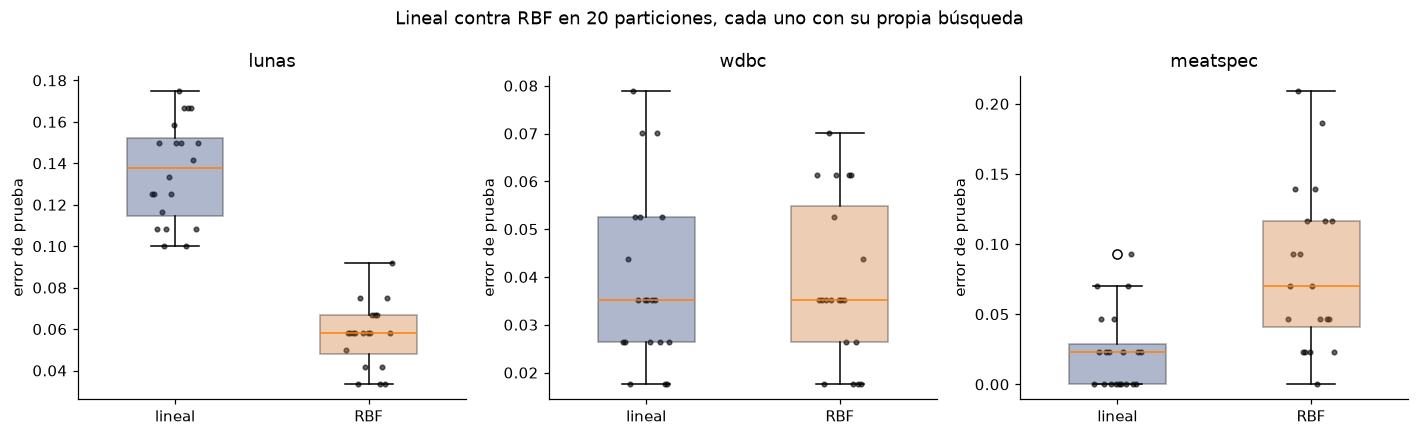

In [18]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4))
for ax, nombre in zip(ejes, CONJUNTOS):
    datos = resultados[resultados.conjunto == nombre]
    cajas = [datos.loc[datos.kernel == k, "err_prueba"] for k in ["linear", "rbf"]]
    caja = ax.boxplot(cajas, patch_artist=True, widths=0.5)
    ax.set_xticks([1, 2], ["lineal", "RBF"])
    for parche, color in zip(caja["boxes"], [AZUL, NARANJA]):
        parche.set_facecolor(color); parche.set_alpha(0.35)
    for k, kernel in enumerate(["linear", "rbf"], start=1):
        ax.scatter(np.full(20, k) + np.linspace(-0.12, 0.12, 20),
                   datos.loc[datos.kernel == kernel, "err_prueba"], s=9, color="k", alpha=0.6)
    ax.set_title(nombre)
    ax.set_ylabel("error de prueba")
fig.suptitle("Lineal contra RBF en 20 particiones, cada uno con su propia búsqueda")
plt.tight_layout()
plt.show()

La geometría de cada conjunto se resume en la fracción de la varianza total —de los datos
estandarizados— que captura cada componente principal.

conjunto     n    p   varianza explicada por las primeras 3 componentes
lunas      600    2   0.6886  0.3114
wdbc       569   30   0.4427  0.1897  0.0939
meatspec   215  100   0.9863  0.0097  0.0028

meatspec: correlacion minima entre dos longitudes de onda = 0.9631
componente  varianza   |corr. con la clase|
         1  0.98626   0.403
         2  0.00970   0.263
         3  0.00279   0.357
         4  0.00114   0.449
         5  0.00006   0.111
         6  0.00003   0.029


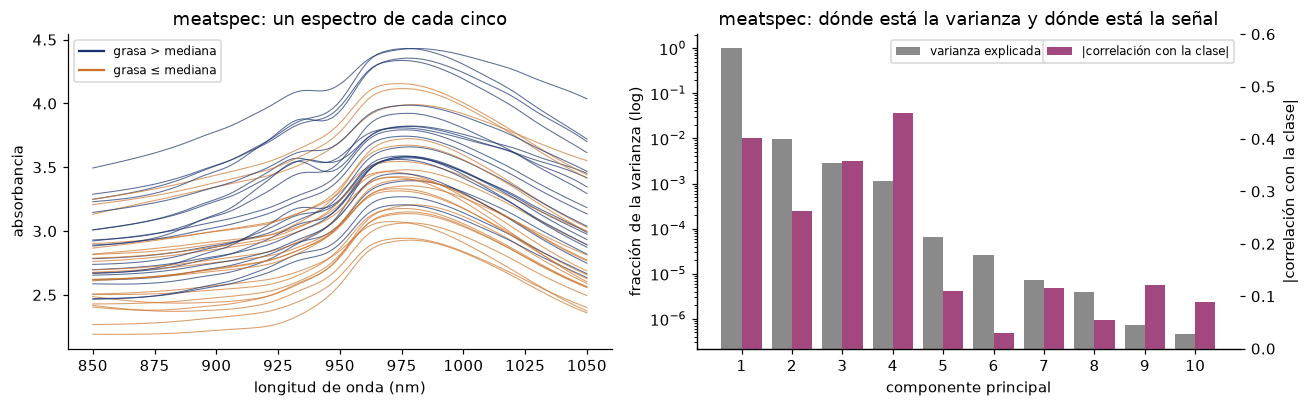

In [19]:
print(f"{'conjunto':<9} {'n':>4} {'p':>4}   varianza explicada por las primeras 3 componentes")
for nombre, (X, y) in CONJUNTOS.items():
    razones = PCA().fit(StandardScaler().fit_transform(X)).explained_variance_ratio_
    print(f"{nombre:<9} {X.shape[0]:>4} {X.shape[1]:>4}   " + "  ".join(f"{r:.4f}" for r in razones[:3]))

correlaciones = np.corrcoef(X_meat.T)[np.triu_indices(X_meat.shape[1], k=1)]
print(f"\nmeatspec: correlacion minima entre dos longitudes de onda = {correlaciones.min():.4f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
longitudes = np.linspace(850, 1050, X_meat.shape[1])
for i in range(0, len(X_meat), 5):
    a1.plot(longitudes, X_meat[i], color=AZUL if y_meat[i] == 1 else NARANJA, lw=0.7, alpha=0.7)
a1.plot([], [], color=AZUL, label="grasa > mediana"); a1.plot([], [], color=NARANJA, label="grasa ≤ mediana")
a1.set_xlabel("longitud de onda (nm)"); a1.set_ylabel("absorbancia"); a1.legend(fontsize=8)
a1.set_title("meatspec: un espectro de cada cinco")
pca_meat = PCA(10).fit(StandardScaler().fit_transform(X_meat))
Z = pca_meat.transform(StandardScaler().fit_transform(X_meat))
corr_clase = np.array([abs(np.corrcoef(Z[:, k], y_meat)[0, 1]) for k in range(10)])
componentes = np.arange(1, 11)
a2.bar(componentes - 0.2, pca_meat.explained_variance_ratio_, width=0.4, color=GRIS,
       label="varianza explicada")
a2.set_yscale("log"); a2.set_ylabel("fracción de la varianza (log)")
a2.set_xlabel("componente principal"); a2.set_xticks(componentes)
a4 = a2.twinx()
a4.bar(componentes + 0.2, corr_clase, width=0.4, color=VIOLETA, label="|correlación con la clase|")
a4.set_ylabel("|correlación con la clase|"); a4.set_ylim(0, 0.6)
a2.legend(loc="upper center", fontsize=8); a4.legend(loc="upper right", fontsize=8)
a2.set_title("meatspec: dónde está la varianza y dónde está la señal")
print("componente  varianza   |corr. con la clase|")
for k in range(6):
    print(f"{k + 1:>10}  {pca_meat.explained_variance_ratio_[k]:.5f}   {corr_clase[k]:.3f}")
plt.tight_layout()
plt.show()

Por último, la celda siguiente pone a prueba el primer motivo de la teoría: repite la
comparación sobre meatspec con una grilla que llega a la esquina donde el RBF imita al
lineal —$\gamma$ hasta $10^{-6}$ y $C$ hasta $10^{6}$—, sobre las primeras $10$ particiones, y
cuenta cuántos ajustes hizo cada kernel.

In [20]:
CS_EXT = [10.0 ** k for k in range(-3, 7)]
GAMMAS_EXT = [10.0 ** k for k in range(-6, 1)]
inicio = time.perf_counter()
extendida = pd.concat([comparar_kernels(X_meat, y_meat, s, CS_EXT, GAMMAS_EXT).assign(semilla=s)
                       for s in range(10)])                 # 10 particiones: la grilla es 2,5 veces mas grande
print(f"grilla extendida: {len(CS_EXT)} ajustes por particion para el lineal, "
      f"{len(CS_EXT) * len(GAMMAS_EXT)} para el RBF ({time.perf_counter() - inicio:.1f} s)\n")
print(extendida.groupby(level="kernel")[["err_validacion", "err_prueba", "n_vs"]].mean().round(4).to_string())
print("\nconfiguraciones elegidas por el RBF (C, gamma) y cuantas veces:")
print(extendida.loc["rbf"].groupby(["C", "gamma"]).size().sort_values(ascending=False).head(6).to_string())

grilla extendida: 10 ajustes por particion para el lineal, 70 para el RBF (9.7 s)

        err_validacion  err_prueba  n_vs
kernel                                  
linear          0.0279      0.0256  14.9
rbf             0.0442      0.0581  18.4

configuraciones elegidas por el RBF (C, gamma) y cuantas veces:
C          gamma  
1000000.0  0.00010    6
           0.00001    2
10000.0    0.01000    1
1000000.0  0.00100    1


### Para analizar

1. Ordenar los tres conjuntos según la ventaja del RBF sobre el lineal —de mayor a menor—
   y relacionar ese orden con la geometría de cada uno: la dimensión $p$, la relación con
   $n$ y la varianza explicada por las primeras componentes.
2. En **wdbc**, ¿la diferencia de error medio entre los dos kernels supera la resolución
   de un conjunto de prueba de $114$ observaciones? Si los dos empatan en exactitud, ¿cuál
   conviene, y con qué argumentos? Considerar los vectores de soporte, el número de
   hiperparámetros y qué se puede leer de un $\mathbf w$ lineal.
3. En **meatspec**, explicar por qué pierde el RBF con el tercer motivo de la teoría. ¿Qué
   indica que la primera componente explique casi toda la varianza, y qué muestra el
   gráfico sobre las componentes que más se correlacionan con la clase?
4. Con la grilla extendida, ¿el RBF alcanza al lineal? ¿Qué configuraciones elige, y qué
   costo tuvo llegar hasta ellas? Relacionar con el desarrollo de $K$ para $\gamma\to0$.
5. Comparar, para cada kernel, el error medio de validación con el de prueba. ¿Cuál de
   los dos es más optimista en validación, y por qué cabía esperarlo?

**Datos de lunas: demostración provisional.** Falta el CSV original del curso; las cifras siguientes corresponden a `make_moons(600, noise=0.25, random_state=42)` y deben recalcularse con `lunas_svm.csv`. Las cifras de wdbc y meatspec sí usan los CSV del curso.

**Respuesta:**

1. Orden de ventaja del RBF: lunas > wdbc > meatspec. En lunas, el error medio de prueba es 0,0571 con RBF y 0,1362 con lineal: ventaja de 7,91 puntos porcentuales y victoria del RBF en las 20 particiones. Su geometría curva en p=2 necesita una frontera no lineal; las componentes explican 68,86 % y 31,14 %. En wdbc, n=569 y p=30, ambos dan 0,0390; las primeras tres componentes explican 44,27 %, 18,97 % y 9,39 %. En meatspec, n=215 y p=100, el lineal da 0,0233 frente a 0,0814 del RBF: pierde por 5,81 puntos y el lineal gana el 80 % de las particiones. Su rango efectivo es mucho menor que p: la primera componente explica 98,63 %. Ni wdbc ni meatspec cumplen n≤p+1; no corresponde afirmar separabilidad arbitraria a partir de ese teorema.
2. La diferencia media en wdbc es cero a cuatro decimales. Para error≈0,0390 y n_prueba=114, un error estándar es sqrt(0,0390×0,9610/114)=0,0181: aproximadamente 1,81 puntos porcentuales, muy superior a la diferencia observada. Con desempeño equivalente conviene el lineal: tiene 37,25 soportes medios frente a 56,55, busca 7 configuraciones frente a 42 y ajusta un hiperparámetro en vez de dos. Además, w permite leer direcciones y pesos de atributos estandarizados, aunque la correlación entre variables limita una interpretación individual y no da causalidad. Las particiones comparten observaciones: 20 repeticiones no son 20 muestras independientes para inferencia estadística.
3. En meatspec casi toda la variación de los espectros sigue una dirección común: PC1 explica 0,98626 y la correlación mínima entre longitudes de onda es 0,9631. La distancia euclídea del RBF da mucho peso a esa variación dominante. La señal de clase también está en direcciones de menor varianza: PC4 explica solo 0,00114 pero tiene |corr|=0,449, mayor que el 0,403 de PC1; PC3 tiene 0,00279 de varianza y correlación 0,357. Un hiperplano puede ponderar esas direcciones sin tener que basarse en la distancia total. Los gráficos apoyan esta explicación; no prueban que sea la única causa de la diferencia.
4. En las primeras 10 particiones, con grilla extendida el RBF no alcanza al lineal: sus errores medios de prueba son 0,0581 y 0,0256, respectivamente. El RBF elige C=10⁶, gamma=10⁻⁴ seis veces; C=10⁶, gamma=10⁻⁵ dos veces; (10⁴,10⁻²) y (10⁶,10⁻³) una vez cada una. La selección se desplaza a C grande y gamma pequeño, compatible con aproximar el kernel lineal compensando la escala 2·gamma del producto interno. Cuesta 70 ajustes por partición para RBF y 10 para lineal: 800 candidatos más 20 ajustes finales en total; la ejecución de ese bloque demoró alrededor de 9,7 s. La grilla original tenía 42 candidatos RBF: ampliar aumenta su costo por un factor 70/42≈1,67. No debe compararse el 0,0581 de 10 particiones con el 0,0814 de 20 como si fueran exactamente la misma muestra.
5. Medias validación → prueba: lunas lineal 0,1258→0,1362 y RBF 0,0446→0,0571; wdbc lineal 0,0180→0,0390 y RBF 0,0158→0,0390; meatspec lineal 0,0198→0,0233 y RBF 0,0547→0,0814. Las brechas son, respectivamente, 0,0104/0,0125, 0,0210/0,0232 y 0,0035/0,0267 (lineal/RBF). En los tres conjuntos el RBF presenta mayor optimismo observado, coherente con elegir el mínimo entre 42 configuraciones en lugar de 7. El mínimo tiene más oportunidades de beneficiarse del ruido de validación. Se usa prueba para estimar desempeño, sin volver a ajustar decisiones según esos errores.


---

# Cierre

### DECIDE

Escribir la conclusión del laboratorio como una regla de decisión: ante un problema de
clasificación nuevo, **qué kernel se prueba primero, qué se mira de los datos para
decidirlo y cómo se elige el resto**. Tres o cuatro líneas, cada afirmación respaldada por
un número de este notebook.

**Datos de lunas: demostración provisional.** Falta el CSV original del curso; las cifras siguientes corresponden a `make_moons(600, noise=0.25, random_state=42)` y deben recalcularse con `lunas_svm.csv`. Las cifras de wdbc y meatspec sí usan los CSV del curso.

**Respuesta:**

Probaría primero el lineal si p es grande respecto de n o los atributos están muy correlacionados: en meatspec (p=100, n=215, PC1=98,63 %) obtuvo 2,33 % de error frente a 8,14 % del RBF.
Si la geometría muestra curvas en pocas dimensiones, probaría RBF: en las lunas de demostración (p=2), redujo el error de 13,62 % a 5,71 %.
Ante rendimiento equivalente, elegiría lineal por simplicidad: en wdbc ambos dieron 3,90 %, con 37,25 soportes medios frente a 56,55.
Ajustaría escalado solo en entrenamiento y C/gamma con validación; reportaría prueba al final y compararía varias particiones, porque en wdbc la resolución de una prueba de 114 casos ronda 1,81 puntos porcentuales.


---

## Para seguir explorando

Fuera del tiempo de clase, sin obligación y sin evaluación:

- **El kernel polinomial.** Repetir el ejercicio 3 con `SVC(kernel="poly", degree=d)` para
  $d=2,3,4$ sobre las lunas. ¿Qué grado se acerca a la frontera del RBF, y con cuántos
  vectores de soporte?
- **Texto.** El repositorio de datasets del curso incluye `Fake_Real_Data.csv`, noticias
  reales y falsas. Con `TfidfVectorizer` se obtienen miles de atributos para unos pocos
  cientos de documentos. ¿Qué predice la teoría del ejercicio 4 sobre lineal contra RBF, y
  qué ocurre con el tiempo de la grilla RBF a medida que crece $n$?
- **Cuando $n$ es grande.** `LinearSVC` resuelve el primal lineal sin pasar por la matriz
  de kernel. Comparar su tiempo con el de `SVC(kernel="linear")` en wdbc replicado $10$
  veces, y explicar la diferencia con el costo del dual.

In [1]:
from __future__ import annotations
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_friedman1
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import mean_squared_error
SEMILLA = 42

def ruta_datos(nombre):
    candidatas = [Path("data") / nombre, Path("../data") / nombre, Path(nombre)]
    ruta = next((p for p in candidatas if p.exists()), None)
    if ruta is None:
        raise FileNotFoundError(f"Falta {nombre}: colocarlo en data/")
    return ruta


In [2]:
AZUL, NARANJA, GRIS = "#19326E", "#CD742A", "#8A8A8A"
def particionar(X: np.ndarray, y: np.ndarray, semilla: int = SEMILLA):
    """Particion estratificada 60/20/20: (X_ent, X_val, X_pru, y_ent, y_val, y_pru)."""
    X_resto, X_pru, y_resto, y_pru = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=semilla)
    X_ent, X_val, y_ent, y_val = train_test_split(
        X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=semilla)
    return X_ent, X_val, X_pru, y_ent, y_val, y_pru


def error(modelo, X: np.ndarray, y: np.ndarray) -> float:
    """Proporcion de observaciones mal clasificadas."""
    return float(np.mean(modelo.predict(X) != y))


def dibujar_frontera(ax, modelo, X: np.ndarray, y: np.ndarray, titulo: str = "",
                     vectores: np.ndarray | None = None) -> None:
    """Regiones de decision, frontera h = 0, margen h = +-1 y vectores de soporte."""
    x1 = np.linspace(X[:, 0].min() - 0.4, X[:, 0].max() + 0.4, 300)
    x2 = np.linspace(X[:, 1].min() - 0.4, X[:, 1].max() + 0.4, 300)
    G1, G2 = np.meshgrid(x1, x2)
    H = modelo.decision_function(np.c_[G1.ravel(), G2.ravel()]).reshape(G1.shape)
    ax.contourf(G1, G2, H > 0, levels=[-0.5, 0.5, 1.5], colors=[NARANJA, AZUL], alpha=0.12)
    ax.contour(G1, G2, H, levels=[-1, 0, 1], colors=[GRIS, "k", GRIS],
               linestyles=["--", "-", "--"], linewidths=[1, 1.6, 1])
    ax.scatter(*X[y == 1].T, s=10, color=AZUL, label="$y=+1$")
    ax.scatter(*X[y == -1].T, s=10, color=NARANJA, label="$y=-1$")
    if vectores is not None:
        ax.scatter(*vectores.T, s=45, facecolors="none", edgecolors="k", linewidths=0.7,
                   label="vector de soporte")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(titulo)



## 1. El kernel polinomial: grados 2, 3 y 4


kernel  grado    C  gamma  error_ent  error_val  error_prueba  n_vs
  poly    2.0 10.0    0.1     0.1417     0.1500        0.1333   126
  poly    3.0  1.0    1.0     0.0583     0.0667        0.0750    75
  poly    4.0  1.0    1.0     0.0472     0.0833        0.0667    64
   rbf    NaN  1.0    1.0     0.0500     0.0500        0.0667    91


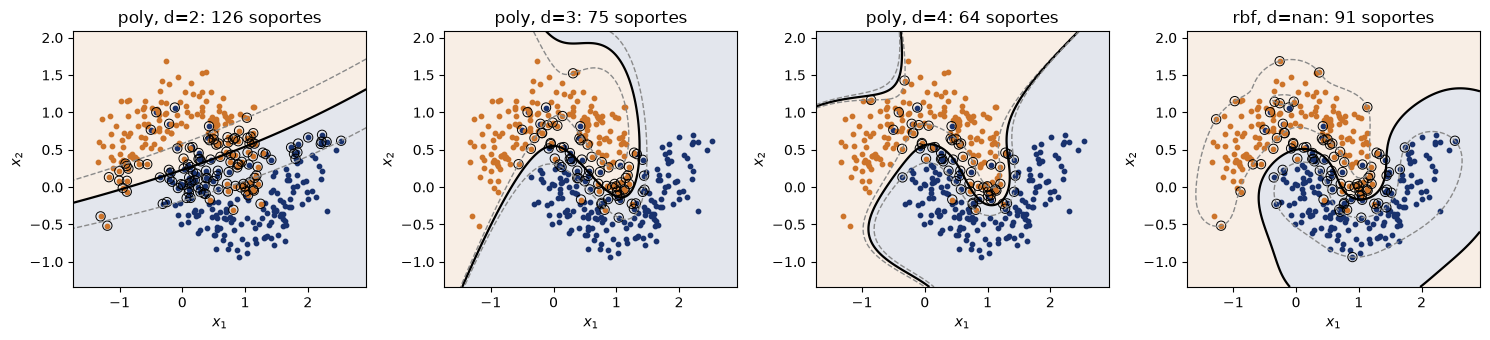

In [3]:
# 1. Polinomial vs RBF: selección únicamente por validación.
lunas_extra = pd.read_csv(ruta_datos("lunas_svm.csv"))
X_extra = lunas_extra[["x1", "x2"]].to_numpy()
y_extra = lunas_extra.y.to_numpy()
Xe, Xv, Xp, ye, yv, yp = particionar(X_extra, y_extra, SEMILLA)
CS_POLY = [0.01, 0.1, 1, 10]
GAMMAS_POLY = [0.01, 0.1, 1]
filas_poly = []
for kernel, grado in [("poly", 2), ("poly", 3), ("poly", 4), ("rbf", None)]:
    candidatos = []
    for C in CS_POLY:
        for gamma in GAMMAS_POLY:
            params = dict(kernel=kernel, C=C, gamma=gamma)
            if grado is not None:
                params.update(degree=grado, coef0=1.0)
            m = make_pipeline(StandardScaler(), SVC(**params, max_iter=500000)).fit(Xe, ye)
            if m[-1].fit_status_ != 0:
                raise RuntimeError(f"No convergió el candidato {params}; revisar la grilla")
            candidatos.append({"C": C, "gamma": gamma, "error_val": error(m, Xv, yv),
                               "n_vs": len(m[-1].support_), "modelo": m})
    mejor = pd.DataFrame(candidatos).sort_values(["error_val", "n_vs"], kind="stable").iloc[0]
    m = mejor.modelo
    filas_poly.append({"kernel": kernel, "grado": grado, "C": mejor.C, "gamma": mejor.gamma,
                       "error_ent": error(m, Xe, ye), "error_val": mejor.error_val,
                       "error_prueba": error(m, Xp, yp), "n_vs": int(mejor.n_vs), "modelo": m})
tabla_poly = pd.DataFrame(filas_poly)
print(tabla_poly.drop(columns="modelo").round(4).to_string(index=False))
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, (_, fila) in zip(axs, tabla_poly.iterrows()):
    scaler, svc = fila.modelo[0], fila.modelo[-1]
    dibujar_frontera(ax, fila.modelo, Xe, ye,
                    titulo=f"{fila.kernel}, d={fila.grado:g}: {int(fila.n_vs)} soportes",
                    vectores=scaler.inverse_transform(svc.support_vectors_))
plt.tight_layout(); plt.show()


**Análisis:**

Se usó el archivo local lunas_svm.csv, con partición 60/20/20 y escalado ajustado solo en entrenamiento. Para cada grado se seleccionó (C, gamma) por error de validación, desempatando por menos soportes; coef0=1 se fijó de antemano. Entre los polinomiales, la mejor validación corresponde al grado 3: C=1, gamma=1, error de validación 0.0667, prueba 0.0750 y 75 soportes. El RBF seleccionado tiene validación 0.0500, prueba 0.0667 y 91 soportes.

La tabla muestra los tres grados y el gráfico permite comparar sus fronteras con la del RBF. El grado 3 se acerca al RBF por validación; el grado 4 empata su error de prueba en esta ejecución, con 64 soportes frente a 91, pero no corresponde cambiar la selección por ese empate de prueba. Un polinomio de grado 2 produce una frontera cuadrática; los grados 3 y 4 pueden representar curvaturas más complejas y asimétricas como las lunas. El resultado depende de C, gamma y coef0, no solo del grado; el mayor grado no necesariamente generaliza mejor. La selección se hizo antes de calcular el error de prueba. Esta comparación usa una partición y una grilla finita, por lo que no implica una superioridad universal de un grado ni del RBF.


## 2. Texto: TF-IDF, lineal vs RBF y costo de la grilla


In [4]:
# 2. Texto: muestra estratificada reproducible, vocabulario aprendido solo en train.
noticias = pd.read_csv(ruta_datos("Fake_Real_Data.csv"))
noticias = noticias.dropna(subset=["Text", "label"])
noticias = noticias[noticias.Text.str.strip().ne("")].drop_duplicates(subset="Text")
# Si el mismo texto tiene dos etiquetas, se conserva la primera; no puede aparecer en dos particiones.
N_TEXTO = min(1200, len(noticias))
if len(noticias) > N_TEXTO:
    noticias, _ = train_test_split(noticias, train_size=N_TEXTO,
                                   stratify=noticias.label, random_state=SEMILLA)
te, tv, tp, ye_txt, yv_txt, yp_txt = particionar(
    noticias.Text.to_numpy(), noticias.label.to_numpy(), SEMILLA)
tfidf = TfidfVectorizer(stop_words="english", min_df=2, max_features=20000,
                        sublinear_tf=True, norm="l2")
Ze = tfidf.fit_transform(te)
Zv, Zp = tfidf.transform(tv), tfidf.transform(tp)
print("Noticias utilizadas:", len(noticias), "TF-IDF train:", Ze.shape,
      "no ceros:", Ze.nnz, "densidad:", Ze.nnz / np.prod(Ze.shape))
CS_TEXTO = [0.01, 0.1, 1, 10, 100]
GAMMAS_TEXTO = [0.1, 1, 10]
filas_txt = []
for kernel in ["linear", "rbf"]:
    inicio = time.perf_counter()
    candidatos = []
    for C in CS_TEXTO:
        for gamma in (GAMMAS_TEXTO if kernel == "rbf" else [None]):
            m = (LinearSVC(C=C, dual="auto", max_iter=20000, random_state=SEMILLA)
                 if kernel == "linear" else SVC(kernel="rbf", C=C, gamma=gamma))
            m.fit(Ze, ye_txt)
            candidatos.append({"C": C, "gamma": gamma,
                               "error_val": error(m, Zv, yv_txt), "modelo": m})
    mejor = pd.DataFrame(candidatos).sort_values(["error_val", "C"], kind="stable").iloc[0]
    m = mejor.modelo
    filas_txt.append({"kernel": kernel, "C": mejor.C, "gamma": mejor.gamma,
                      "error_val": mejor.error_val, "error_prueba": error(m, Zp, yp_txt),
                      "n_vs": len(m.support_) if kernel == "rbf" else np.nan,
                      "candidatos": len(candidatos), "segundos_grilla": time.perf_counter() - inicio})
tabla_texto = pd.DataFrame(filas_txt)
print(tabla_texto.round(4).to_string(index=False))

# Costo de UN candidato RBF, sobre subconjuntos crecientes; mediana de tres repeticiones.
tiempos_txt = []
for n in [len(ye_txt) // 4, len(ye_txt) // 2, len(ye_txt)]:
    indices = np.arange(len(ye_txt))
    if n < len(indices):
        indices, _ = train_test_split(indices, train_size=n, stratify=ye_txt,
                                      random_state=SEMILLA)
    medidas = []
    for _ in range(3):
        inicio = time.perf_counter()
        SVC(C=1, gamma=1, kernel="rbf").fit(Ze[indices], ye_txt[indices])
        medidas.append(time.perf_counter() - inicio)
    tiempos_txt.append({"n": n, "segundos": np.median(medidas),
                        "pares_kernel": n * n, "MB_gram_densa_teorica": 8 * n * n / 1e6})
tiempos_txt = pd.DataFrame(tiempos_txt)
print()
print("Costo de un candidato RBF (gamma=1, C=1):")
print(tiempos_txt.round(4).to_string(index=False))


Noticias utilizadas: 1200 TF-IDF train: (720, 8940) no ceros: 106262 densidad: 0.016508513547104153
kernel    C  gamma  error_val  error_prueba  n_vs  candidatos  segundos_grilla
linear  1.0    NaN        0.0        0.0167   NaN           5           0.0224
   rbf 10.0    0.1        0.0        0.0125 504.0          15           7.7467

Costo de un candidato RBF (gamma=1, C=1):
  n  segundos  pares_kernel  MB_gram_densa_teorica
180    0.0255         32400                 0.2592
360    0.0953        129600                 1.0368
720    0.3778        518400                 4.1472


**Análisis:**

Se tomó una muestra estratificada reproducible de 1200 noticias, sin textos duplicados, del CSV del curso. TF-IDF se ajustó solo con los 720 textos de entrenamiento: hay 8940 atributos y densidad 0.0165. Validación elige los hiperparámetros y prueba se usa una sola vez por modelo. Se comparó LinearSVC (lineal) con SVC RBF; no se escaló el texto con StandardScaler porque TF-IDF ya usa normalización L2 y se conserva la representación dispersa.

El lineal obtuvo validación 0.0000 y prueba 0.0167, con cinco candidatos y 0.022 s de búsqueda. El RBF obtuvo 0.0000 y 0.0125, con 15 candidatos y 7.747 s. Son resultados de una muestra y una partición, no del CSV completo. En texto, miles de atributos para cientos de ejemplos ya permiten hiperplanos flexibles: el lineal es una primera opción razonable, aunque eso no garantiza que gane siempre.

Para un candidato RBF fijo, al aumentar n de 180 a 720 el tiempo mediano pasó de 0.0255 a 0.3778 s. La cantidad de pares crece como n²; duplicar n cuadruplica las entradas de una matriz Gram completa. La tabla da su memoria teórica en float64, no una medición de RAM: SVC usa una caché y no necesariamente materializa toda la matriz. El tiempo de ajuste no tiene un exponente universal, porque también depende de la dispersión, los soportes y la convergencia. Una grilla RBF repite ese costo por cada combinación de C y gamma, mientras el lineal solo ajusta C.


## 3. Cuando n es grande: SVC lineal vs LinearSVC


In [5]:
# 3. wdbc x10: dividir primero, replicar únicamente entrenamiento.
bc = load_breast_cancer()
Xb, yb = bc.data, np.where(bc.target == 0, 1, -1)
Xeb, Xpb, yeb, ypb = train_test_split(Xb, yb, test_size=0.2,
                                    stratify=yb, random_state=SEMILLA)
scaler_b = StandardScaler().fit(Xeb)
Zeb, Zpb = scaler_b.transform(Xeb), scaler_b.transform(Xpb)
medidas_grandes = []
for factor in [1, 10]:
    Zrep, yrep = np.tile(Zeb, (factor, 1)), np.tile(yeb, factor)
    for nombre in ["SVC linear (dual)", "LinearSVC (primal)"]:
        medidas = []
        for _ in range(3):
            m = (SVC(kernel="linear", C=1, tol=1e-4)
                 if nombre.startswith("SVC") else
                 LinearSVC(C=1, dual=False, loss="squared_hinge", tol=1e-4,
                           max_iter=20000, random_state=SEMILLA))
            inicio = time.perf_counter()
            m.fit(Zrep, yrep)
            medidas.append(time.perf_counter() - inicio)
        medidas_grandes.append({"modelo": nombre, "factor": factor, "n_train": len(yrep),
                                 "segundos_fit": np.median(medidas),
                                 "error_prueba": error(m, Zpb, ypb),
                                 "n_vs": len(m.support_) if hasattr(m, "support_") else np.nan})
tiempos_grandes = pd.DataFrame(medidas_grandes)
print("Misma prueba independiente:", len(ypb), "observaciones; p=30; C=1")
print(tiempos_grandes.round(5).to_string(index=False))


Misma prueba independiente: 114 observaciones; p=30; C=1
            modelo  factor  n_train  segundos_fit  error_prueba  n_vs
 SVC linear (dual)       1      455       0.00276       0.03509  38.0
LinearSVC (primal)       1      455       0.00127       0.03509   NaN
 SVC linear (dual)      10     4550       0.03827       0.02632 185.0
LinearSVC (primal)      10     4550       0.01472       0.04386   NaN


**Análisis:**

Se dividió wdbc antes de replicar, para que ninguna copia de una observación de entrenamiento aparezca en prueba. Se replicaron las 455 observaciones de entrenamiento diez veces: 4550 filas, pero solo 455 ejemplos distintos. Los 114 ejemplos de prueba permanecen independientes. Las cifras son medianas de tres ajustes, con C=1 y escalado común.

En n=455, SVC lineal demoró 0.00276 s y LinearSVC 0.00127 s; en n=4550, demoraron 0.03827 s y 0.01472 s. En la réplica x10 sus errores de prueba fueron 0.0263 y 0.0439.

SVC usa una formulación dual con variables asociadas a ejemplos y cálculos de kernel incluso con kernel lineal. LinearSVC se configuró con dual=False para resolver el primal en 30 coeficientes, sin una matriz de kernel n×n. Eso favorece su costo cuando n es grande respecto de p. No son objetivos exactamente iguales: SVC usa hinge loss y LinearSVC aquí squared_hinge, con diferencias en el tratamiento del intercepto; no se espera igualdad exacta de predicciones. Replicar con C fijo también multiplica por diez el término de pérdida de cada ejemplo y equivale, en cada formulación, a aumentar C respecto del conjunto original. Para aislar el efecto computacional manteniendo ese balance, una comparación adicional usaría C=0,1 en la réplica x10. Replicar mide costo y ponderación, no el beneficio de adquirir datos nuevos.
